# Predicting how many minutes a flight will leave late

*Part of **D3** of the flight-delay project: training and comparing the delay-prediction models.*

This notebook trains two models, a **Random Forest** and a **Gradient Boosted** tree ensemble, to predict a flight's **departure delay in minutes**. Both learn from the project database (`flights.db`, 20.9M domestic flights from 2023–2025) and are tested on a random 20% of flights they never saw.

**Target.** `delay_min = max(dep_delay, 0)`: minutes between the scheduled and actual gate departure, with early departures counted as 0 (the same definition as BTS's *DepDelayMinutes*). Cancelled and diverted flights have no departure delay, so they're left out.

**Inputs.** Everything comes from the `flights_combined` view plus two congestion counts:

| Group | What it is |
| --- | --- |
| Schedule | airline, origin, destination, month, weekday, day of month, departure and arrival hour, scheduled duration, distance |
| Weather | daily weather at the origin and at the destination on the flight date: weather code, high/low temperature, precipitation, rain, snow, hours of precipitation, peak wind and gusts |
| Carrier quality | **last month's** record for this airline at both airports (share delayed 15+, share cancelled, average delay, and the share of delays caused by the carrier, weather, the air-traffic system and late-arriving aircraft), last month's on-time % for the scheduled hour at both airports, and the airline's mishandled-bag rate |
| Congestion | how many departures are scheduled at the origin that day and in that hour |

**Leakage safeguards** (from the dashboard's *Leakage safeguards* page):
1. Only columns that are known before the flight leaves are used. Actual times, taxi times, arrival delay and delay-cause minutes are never loaded, and a cell below asserts that none slipped in.
2. Monthly statistics are always the **previous** month's, so a flight never sees totals that include itself.
3. The split is a **random 80/20** across all three years, so the models learn from the most recent flights (2025) as well as older ones. They'll be used to predict present-day flights. The test 20% is set aside before anything is fit, including the airport/airline encodings, the baselines and the tuning, and it's scored only once at the end.

Two known optimisms:
* A random split puts flights from the same day and airport on both sides. They share that day's weather and congestion, so test scores are a little better than you'd see on a day the model has never seen.
* The weather is what was *observed* that day. A real forecast a day ahead is close but not identical, so expect slightly worse accuracy on future flights.

## 1 · Setup

In [1]:
import json
import os
import sqlite3
import sys
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import KFold, train_test_split
from sklearn.metrics import (mean_absolute_error, median_absolute_error, r2_score,
                             roc_auc_score, root_mean_squared_error)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import TargetEncoder

# Same location rule as data_pipeline/paths.py
DATA_DIR = Path(os.environ.get("FLIGHT_DATA_DIR", Path.home() / "flight_data"))
DB_PATH = DATA_DIR / "flights.db"
MODEL_DIR = DATA_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

SAMPLE_RATE = int(os.environ.get("DELAY_SAMPLE_RATE", 10))   # keep 1 in every SAMPLE_RATE flights
SAMPLE_PATH = MODEL_DIR / f"sample_1in{SAMPLE_RATE}.pkl"
RANDOM_STATE = 42

pd.set_option("display.float_format", "{:,.3f}".format)
pd.set_option("display.max_columns", 80)
print("database:", DB_PATH, f"({DB_PATH.stat().st_size / 1e9:.1f} GB)")

database: C:\Users\Jbeck\flight_data\flights.db (4.8 GB)


In [2]:
# Chart style: light surface, recessive grid, one fixed color per model everywhere.
SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e0"
RF_COLOR, HGB_COLOR, BASE_COLOR, ACTUAL_COLOR = "#2a78d6", "#eb6834", "#a3a29c", "#0b0b0b"
COLORS = {"Random Forest": RF_COLOR, "Gradient Boosting": HGB_COLOR, "Baseline: always 0": BASE_COLOR,
          "Baseline: overall mean": BASE_COLOR, "Baseline: airline × origin × hour": BASE_COLOR}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "font.size": 10,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK,
    "lines.linewidth": 2, "legend.frameon": False,
})

## 2 · Load a sample of flights

21M rows won't fit comfortably in memory alongside two tree ensembles, so we take a random 1-in-10 sample (about 2M flights). That's still far more than the models need to learn stable patterns.

SQLite's `random()` can't be seeded, so the sample is saved to a pickle file the first time and reloaded after that, which keeps reruns reproducible. Delete the file to draw a new sample.

The congestion counts are computed from the **full** `flights` table (cancelled flights included, since they were on the schedule), so sampling doesn't thin them out. An airline publishes its schedule months ahead, so these counts are known before departure, and the live board can compute the same thing from the AeroDataBox schedule.

In [3]:
WEATHER_FIELDS = ["weather_code", "temp_max_f", "temp_min_f", "precip_in", "rain_in", "snowfall_in",
                  "precip_hours", "wind_max_mph", "gust_max_mph"]
PREV_FIELDS = ["arr_flights", "del15_rate", "cancel_rate", "avg_delay_min", "carrier_rate",
               "weather_rate", "nas_rate", "late_aircraft_rate"]

LOAD_COLUMNS = (
    ["flight_date", "year", "month", "day_of_month", "day_of_week", "airline", "origin", "dest",
     "sched_dep_time", "sched_arr_time", "sched_elapsed_time", "distance", "dep_delay"]
    + [f"{side}_{c}" for side in ("origin", "dest") for c in WEATHER_FIELDS]
    + [f"{side}_prev_{c}" for side in ("origin", "dest") for c in PREV_FIELDS]
    + ["origin_prev_hour_dep_ontime_pct", "dest_prev_hour_arr_ontime_pct",
       "airline_prev_bags_mishandled_per_100"]
)


def load_sample():
    con = sqlite3.connect(f"file:{DB_PATH.as_posix()}?mode=ro", uri=True)
    start = time.time()
    flights = pd.read_sql(f"""
        SELECT {', '.join(LOAD_COLUMNS)}
        FROM flights_combined
        WHERE cancelled = 0 AND diverted = 0 AND dep_delay IS NOT NULL
          AND abs(random()) % {SAMPLE_RATE} = 0
    """, con)
    print(f"sampled {len(flights):,} flights in {time.time() - start:.0f}s")

    start = time.time()
    hourly = pd.read_sql("""
        SELECT origin, flight_date, sched_dep_time / 100 AS dep_hour, COUNT(*) AS origin_hour_flights
        FROM flights
        GROUP BY origin, flight_date, dep_hour
    """, con)
    con.close()
    hourly["origin_day_flights"] = hourly.groupby(["origin", "flight_date"])["origin_hour_flights"].transform("sum")
    print(f"counted scheduled departures for {len(hourly):,} airport-hours in {time.time() - start:.0f}s")

    flights["dep_hour"] = flights["sched_dep_time"] // 100
    flights = flights.merge(hourly, on=["origin", "flight_date", "dep_hour"], how="left")
    floats = flights.select_dtypes("float64").columns
    flights[floats] = flights[floats].astype("float32")
    return flights


if SAMPLE_PATH.exists():
    raw = pd.read_pickle(SAMPLE_PATH)
    print(f"loaded cached sample: {len(raw):,} flights from {SAMPLE_PATH}")
else:
    raw = load_sample()
    raw.to_pickle(SAMPLE_PATH)
    print(f"saved sample to {SAMPLE_PATH}")

raw.groupby("year").size().rename("flights in sample").to_frame()

loaded cached sample: 2,057,321 flights from C:\Users\Jbeck\flight_data\models\sample_1in10.pkl


,flights in sample
year,
2023,673146
2024,696008
2025,688167


## 3 · Features and target

In [4]:
CATEGORICAL = ["airline", "origin", "dest"]
SCHEDULE = ["month", "day_of_week", "day_of_month", "dep_hour", "arr_hour",
            "sched_elapsed_time", "distance"] + CATEGORICAL
WEATHER = ([f"{side}_{c}" for side in ("origin", "dest") for c in WEATHER_FIELDS]
           + [f"{side}_{flag}" for side in ("origin", "dest") for flag in ("storm", "snow")])
CARRIER_QUALITY = ([f"{side}_prev_{c}" for side in ("origin", "dest") for c in PREV_FIELDS]
                   + ["origin_prev_hour_dep_ontime_pct", "dest_prev_hour_arr_ontime_pct",
                      "airline_prev_bags_mishandled_per_100"])
CONGESTION = ["origin_day_flights", "origin_hour_flights"]
FEATURE_GROUPS = {"Schedule": SCHEDULE, "Weather": WEATHER,
                  "Carrier quality": CARRIER_QUALITY, "Congestion": CONGESTION}
FEATURES = [f for group in FEATURE_GROUPS.values() for f in group]

df = raw.copy()
df["delay_min"] = df["dep_delay"].clip(lower=0)
df["dep_hour"] = df["dep_hour"] % 24                 # 2400 means midnight
df["arr_hour"] = (df["sched_arr_time"] // 100) % 24
for side in ("origin", "dest"):
    wcode = df[f"{side}_weather_code"]
    df[f"{side}_storm"] = (wcode >= 95).astype("float32")                                # thunderstorm
    df[f"{side}_snow"] = (wcode.between(71, 77) | wcode.between(85, 86)).astype("float32")  # snow, snow showers

# Gradient boosting's native categorical support allows at most 255 levels, and there are ~360
# airports. Keep the 250 busiest (by training flights) and group the rest, under 1% of flights, as OTHER.
MAX_LEVELS = 250
# Random 80/20 split, drawn here so the kept levels below come from the training rows only.
train_idx, test_idx = train_test_split(df.index, test_size=0.2, random_state=RANDOM_STATE)
is_train = df.index.isin(train_idx)
KEPT_LEVELS = {}
for col in CATEGORICAL:
    top = df.loc[is_train, col].value_counts().index[:MAX_LEVELS]
    KEPT_LEVELS[col] = sorted(top)
    df[col] = pd.Categorical(df[col].where(df[col].isin(top), "OTHER"),
                             categories=KEPT_LEVELS[col] + ["OTHER"])
    print(f"{col}: {df[col].nunique()} levels, {(df[col] == 'OTHER').mean():.2%} of flights grouped as OTHER")

print(f"\n{len(FEATURES)} features:", {g: len(c) for g, c in FEATURE_GROUPS.items()})
df[FEATURES + ["delay_min"]].head()

airline: 15 levels, 0.00% of flights grouped as OTHER


origin: 251 levels, 0.75% of flights grouped as OTHER


dest: 251 levels, 0.74% of flights grouped as OTHER

53 features: {'Schedule': 10, 'Weather': 22, 'Carrier quality': 19, 'Congestion': 2}


,month,day_of_week,day_of_month,dep_hour,arr_hour,sched_elapsed_time,distance,airline,origin,dest,origin_weather_code,origin_temp_max_f,origin_temp_min_f,origin_precip_in,origin_rain_in,origin_snowfall_in,origin_precip_hours,origin_wind_max_mph,origin_gust_max_mph,dest_weather_code,dest_temp_max_f,dest_temp_min_f,dest_precip_in,dest_rain_in,dest_snowfall_in,dest_precip_hours,dest_wind_max_mph,dest_gust_max_mph,origin_storm,origin_snow,dest_storm,dest_snow,origin_prev_arr_flights,origin_prev_del15_rate,origin_prev_cancel_rate,origin_prev_avg_delay_min,origin_prev_carrier_rate,origin_prev_weather_rate,origin_prev_nas_rate,origin_prev_late_aircraft_rate,dest_prev_arr_flights,dest_prev_del15_rate,dest_prev_cancel_rate,dest_prev_avg_delay_min,dest_prev_carrier_rate,dest_prev_weather_rate,dest_prev_nas_rate,dest_prev_late_aircraft_rate,origin_prev_hour_dep_ontime_pct,dest_prev_hour_arr_ontime_pct,airline_prev_bags_mishandled_per_100,origin_day_flights,origin_hour_flights,delay_min
0,1,2,3,8,9,65.000,101.000,9E,BDL,LGA,61,41.800,32.700,0.398,0.398,0.000,18.000,5.000,11.600,63,55.700,44.700,0.488,0.488,0.000,10.000,12.300,20.100,0.000,0.000,0.000,0.000,102.000,0.206,0.039,68.571,0.072,0.000,0.021,0.113,"2,603.000",0.205,0.043,73.041,0.030,0.010,0.130,0.034,NaN,NaN,NaN,61,3,0.000
1,1,6,21,15,17,140.000,585.000,9E,LGA,CVG,51,42.400,29.000,0.004,0.004,0.000,1.000,10.900,19.700,3,40.800,29.300,0.000,0.000,0.000,0.000,6.300,13.000,0.000,0.000,0.000,0.000,"2,603.000",0.205,0.043,73.041,0.030,0.010,0.130,0.034,487.000,0.228,0.029,62.090,0.091,0.005,0.054,0.078,NaN,NaN,NaN,265,18,0.000
2,1,2,17,21,22,59.000,147.000,9E,LGA,OTHER,55,44.600,27.200,0.083,0.083,0.000,2.000,8.100,13.200,71,38.600,20.800,0.055,0.047,0.055,5.000,6.600,12.100,0.000,0.000,0.000,1.000,"2,603.000",0.205,0.043,73.041,0.030,0.010,0.130,0.034,30.000,0.100,0.033,39.333,0.033,0.021,0.046,0.000,NaN,NaN,NaN,520,24,15.000
3,1,5,27,21,22,59.000,147.000,9E,LGA,OTHER,51,43.300,28.300,0.004,0.004,0.000,1.000,12.200,21.700,71,31.800,20.400,0.008,0.000,0.055,2.000,9.400,19.900,0.000,0.000,0.000,1.000,"2,603.000",0.205,0.043,73.041,0.030,0.010,0.130,0.034,30.000,0.100,0.033,39.333,0.033,0.021,0.046,0.000,NaN,NaN,NaN,520,24,0.000
4,1,7,29,13,15,76.000,331.000,9E,ATL,FAY,63,59.600,39.500,0.413,0.413,0.000,5.000,10.100,17.200,55,61.200,33.200,0.047,0.047,0.000,1.000,6.500,10.500,0.000,0.000,0.000,0.000,"1,691.000",0.152,0.004,84.545,0.036,0.004,0.036,0.076,14.000,0.071,0.000,42.000,0.007,0.000,0.000,0.064,NaN,NaN,NaN,916,41,0.000


**Leakage check.** `dashboard/catalog.py` tags every `flights` column with a role. Anything tagged *outcome* (recorded after the flight) or *target* must not be a model input.

In [5]:
catalog_dir = next(p / "dashboard" for p in (Path.cwd(), Path.cwd().parent) if (p / "dashboard" / "catalog.py").exists())
sys.path.insert(0, str(catalog_dir))
from catalog import FLIGHT_COLUMNS as CATALOG, OUTCOME, TARGET

forbidden = {col for col, (role, _) in CATALOG.items() if role in (OUTCOME, TARGET)} | {"tail_number", "flight_number"}
leaks = forbidden & set(FEATURES)
assert not leaks, f"leaky features: {leaks}"
print(f"OK: none of the {len(forbidden)} outcome/target/identifier columns are features.")

OK: none of the 22 outcome/target/identifier columns are features.


### What the target looks like

In [6]:
train_all = df[is_train]
q = train_all["delay_min"].quantile([0.5, 0.75, 0.9, 0.95, 0.99, 0.995, 0.999])
print(f"mean {train_all['delay_min'].mean():.1f} min · {(train_all['delay_min'] == 0).mean():.1%} left on time or early · "
      f"{(train_all['delay_min'] >= 15).mean():.1%} left 15+ min late · max {train_all['delay_min'].max():,.0f} min")
q.rename("minutes").rename_axis("percentile").to_frame().T

mean 16.0 min · 62.3% left on time or early · 21.0% left 15+ min late · max 4,352 min


percentile,0.500,0.750,0.900,0.950,0.990,0.995,0.999
minutes,0.000,9.000,44.000,83.000,216.000,298.000,765.000


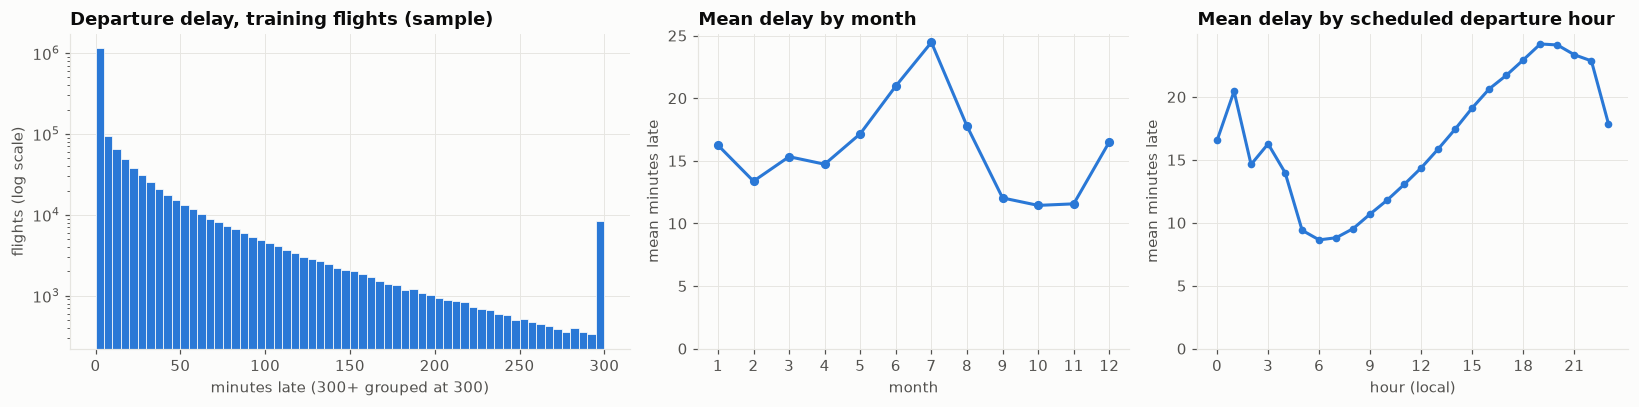

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), gridspec_kw={"width_ratios": [1.3, 1, 1]})

ax = axes[0]
ax.hist(train_all["delay_min"].clip(upper=300), bins=np.arange(0, 305, 5), color=RF_COLOR, edgecolor=SURFACE, linewidth=0.5)
ax.set_yscale("log")
ax.set(title="Departure delay, training flights (sample)", xlabel="minutes late (300+ grouped at 300)", ylabel="flights (log scale)")

ax = axes[1]
by_month = train_all.groupby("month")["delay_min"].mean()
ax.plot(by_month.index, by_month.values, color=RF_COLOR, marker="o", markersize=5)
ax.set(title="Mean delay by month", xlabel="month", ylabel="mean minutes late", xticks=range(1, 13))
ax.set_ylim(bottom=0)

ax = axes[2]
by_hour = train_all.groupby("dep_hour")["delay_min"].mean()
ax.plot(by_hour.index, by_hour.values, color=RF_COLOR, marker="o", markersize=4)
ax.set(title="Mean delay by scheduled departure hour", xlabel="hour (local)", ylabel="mean minutes late", xticks=range(0, 24, 3))
ax.set_ylim(bottom=0)
fig.tight_layout()
plt.show()

Most flights leave on time, and a long tail leaves hours late. Delays build through the day, because a late plane makes every later flight on its rotation late too. They also peak in summer storm season and around the winter holidays.

## 4 · Train / validation / test split

* **Test:** a random **20%** of the sampled flights from all three years, set aside before any fitting and scored only once at the end.
* **Train:** the other **80%**. A random 20% of the training rows is held out as a *validation* set for choosing hyperparameters, and the rest is used to fit. Once the settings are chosen, the final models are refit on the whole 80%.

**Clipping the training target.** A handful of flights leave 10–30 hours late. With squared-error loss those few rows would pull every prediction upward. So the models are *fit* on delays clipped at the training set's 99.5th percentile, but every score below is measured against the **real, unclipped** delay.

In [8]:
train = df.loc[train_idx]
test = df.loc[test_idx]
is_valid = train.index.isin(train_test_split(train.index, test_size=0.2, random_state=RANDOM_STATE)[1])
fit_part, valid_part = train[~is_valid], train[is_valid]

CLIP_MIN = float(train["delay_min"].quantile(0.995))


def y_fit(frame):
    return frame["delay_min"].clip(upper=CLIP_MIN)


def scores(y_true, y_pred):
    return {"RMSE": root_mean_squared_error(y_true, y_pred),
            "R²": r2_score(y_true, y_pred),
            "MAE": mean_absolute_error(y_true, y_pred),
            "Median abs. error": median_absolute_error(y_true, y_pred)}


print("test flights by year:", test["year"].value_counts().sort_index().to_dict())
print(f"fit {len(fit_part):,} · validation {len(valid_part):,} · train total {len(train):,} · test {len(test):,}")
print(f"training target clipped at {CLIP_MIN:.0f} minutes ({(train['delay_min'] > CLIP_MIN).mean():.2%} of training flights)")

test flights by year: {2023: 134375, 2024: 139073, 2025: 138017}
fit 1,316,684 · validation 329,172 · train total 1,645,856 · test 411,465
training target clipped at 298 minutes (0.50% of training flights)


**Which score to judge by.** The board shows an *expected* delay, the average number of minutes flights like this one leave late. Both models are fit with squared-error loss, which is exactly what produces that average. So the main scores are **RMSE** (typical size of a miss, with big misses weighted more) and **R²** (the share of the flight-to-flight variation in delay the model explains), which measure the same thing the models aim for.

**MAE** (the average minutes off) is reported too, with one caveat. MAE is minimized by the *median*, not the mean, and the median flight leaves on time. A model that always says "0 minutes" gets a decent MAE while being useless for spotting risky flights. That's why the "always 0" baseline is in the table below.

## 5 · Baselines

A model is only useful if it beats something simple. We use three baselines:
* **Always 0:** every flight leaves on time. This is the median flight, and the best constant for MAE.
* **Overall mean:** predict the average training delay for every flight. This is the best constant for RMSE, so its R² is about 0.
* **Airline × origin × hour:** predict the average delay of that airline's flights from that airport in that departure hour, from the training flights. Groups with fewer than 30 flights fall back to the overall mean. This is roughly what you'd get from a lookup table of historical on-time performance.

In [9]:
GLOBAL_MEAN = float(y_fit(train).mean())
KEY = ["airline", "origin", "dep_hour"]
group_stats = (train.assign(y=y_fit(train)).groupby(KEY, observed=True)["y"].agg(["mean", "count"]))
group_mean = group_stats.loc[group_stats["count"] >= 30, "mean"].rename("group_mean")


def baseline_zero(frame):
    return np.zeros(len(frame))


def baseline_overall(frame):
    return np.full(len(frame), GLOBAL_MEAN)


def baseline_group(frame):
    return frame[KEY].join(group_mean, on=KEY)["group_mean"].fillna(GLOBAL_MEAN).to_numpy()


BASELINES = {"Baseline: always 0": baseline_zero, "Baseline: overall mean": baseline_overall,
             "Baseline: airline × origin × hour": baseline_group}
print(f"overall mean {GLOBAL_MEAN:.1f} min · {len(group_mean):,} airline × origin × hour groups · scores on the validation months:")
pd.DataFrame({name: scores(valid_part["delay_min"], f(valid_part)) for name, f in BASELINES.items()}).T

overall mean 14.8 min · 9,089 airline × origin × hour groups · scores on the validation months:


,RMSE,R²,MAE,Median abs. error
Baseline: always 0,56.973,-0.086,16.033,0.000
Baseline: overall mean,54.685,-0.001,22.570,14.775
Baseline: airline × origin × hour,54.008,0.024,21.431,12.756


## 6 · Random Forest

A Random Forest averages many deep decision trees, each grown on a random subset of flights and features. scikit-learn's forest needs numeric inputs, so airline, origin and destination are **target encoded**: each code is replaced by the average delay for that code. The encoder is cross-fitted, so a flight's own delay never goes into its encoding. Missing values, such as the hourly on-time % at the smaller airports, are handled natively by the trees.

To keep training time reasonable on ~1.4M rows, each tree sees a random 30% of the flights (`max_samples=0.3`) and half the features at each split.

First, a quick check of leaf size on the validation months, using smaller 60-tree forests:

In [10]:
def make_rf(**overrides):
    params = dict(n_estimators=200, max_depth=20, min_samples_leaf=50, max_features=0.5,
                  max_samples=0.3, n_jobs=-1, random_state=RANDOM_STATE)
    params.update(overrides)
    encode = ColumnTransformer(
        [("target_encode", TargetEncoder(target_type="continuous",
                                         cv=KFold(5, shuffle=True, random_state=RANDOM_STATE)), CATEGORICAL)],
        remainder="passthrough", verbose_feature_names_out=False)
    return Pipeline([("encode", encode), ("forest", RandomForestRegressor(**params))])


rf_search = []
for leaf in [20, 50, 200]:
    start = time.time()
    model = make_rf(n_estimators=60, min_samples_leaf=leaf).fit(fit_part[FEATURES], y_fit(fit_part))
    rf_search.append({"min_samples_leaf": leaf, **scores(valid_part["delay_min"], model.predict(valid_part[FEATURES])),
                      "fit seconds": time.time() - start})
rf_search = pd.DataFrame(rf_search)
RF_BEST = {"min_samples_leaf": int(rf_search.loc[rf_search["RMSE"].idxmin(), "min_samples_leaf"])}
print("best:", RF_BEST)
rf_search

best: {'min_samples_leaf': 20}


,min_samples_leaf,RMSE,R²,MAE,Median abs. error,fit seconds
0,20,53.344,0.048,20.831,10.993,118.116
1,50,53.420,0.045,20.862,11.150,110.730
2,200,53.555,0.040,20.990,11.385,98.752


In [11]:
start = time.time()
rf = make_rf(**RF_BEST).fit(train[FEATURES], y_fit(train))
print(f"Random Forest: 200 trees fit on {len(train):,} flights in {(time.time() - start) / 60:.1f} min")

Random Forest: 200 trees fit on 1,645,856 flights in 9.5 min


## 7 · Gradient Boosting

Gradient boosting builds trees **one after another**, each correcting the errors of the ones before it. We use scikit-learn's `HistGradientBoostingRegressor`, the same algorithm as LightGBM. It bins each feature into histograms, which makes it fast on millions of rows, and it handles missing values and the airline/airport codes **natively** as categories, with no encoding.

Training stops early once a held-out 10% of the training rows stops improving, so the number of trees is chosen automatically. We tune the learning rate and tree size on the validation months:

In [12]:
def make_hgb(**overrides):
    params = dict(learning_rate=0.05, max_iter=1500, max_leaf_nodes=63, min_samples_leaf=100,
                  l2_regularization=1.0, categorical_features="from_dtype", early_stopping=True,
                  validation_fraction=0.1, n_iter_no_change=30, random_state=RANDOM_STATE)
    params.update(overrides)
    return HistGradientBoostingRegressor(**params)


hgb_search = []
for lr in [0.05, 0.1]:
    for leaves in [31, 127]:
        start = time.time()
        model = make_hgb(learning_rate=lr, max_leaf_nodes=leaves).fit(fit_part[FEATURES], y_fit(fit_part))
        hgb_search.append({"learning_rate": lr, "max_leaf_nodes": leaves, "trees": model.n_iter_,
                           **scores(valid_part["delay_min"], model.predict(valid_part[FEATURES])),
                           "fit seconds": time.time() - start})
hgb_search = pd.DataFrame(hgb_search)
best_row = hgb_search.loc[hgb_search["RMSE"].idxmin()]
HGB_BEST = {"learning_rate": float(best_row["learning_rate"]), "max_leaf_nodes": int(best_row["max_leaf_nodes"])}
print("best:", HGB_BEST)
hgb_search

best: {'learning_rate': 0.05, 'max_leaf_nodes': 127}


,learning_rate,max_leaf_nodes,trees,RMSE,R²,MAE,Median abs. error,fit seconds
0,0.050,31,958,53.083,0.057,20.500,10.789,112.211
1,0.050,127,430,53.008,0.060,20.426,10.578,89.277
2,0.100,31,492,53.108,0.056,20.524,10.763,46.174
3,0.100,127,203,53.048,0.058,20.453,10.590,34.345


In [13]:
start = time.time()
hgb = make_hgb(**HGB_BEST).fit(train[FEATURES], y_fit(train))
print(f"Gradient Boosting: {hgb.n_iter_} trees fit on {len(train):,} flights in {(time.time() - start) / 60:.1f} min")

Gradient Boosting: 446 trees fit on 1,645,856 flights in 1.4 min


## 8 · Test on the held-out 20%

Both models and all three baselines are now scored on the held-out 20% of flights. None of these were used for fitting or tuning.

In [14]:
y_test = test["delay_min"].to_numpy()
preds = {name: f(test) for name, f in BASELINES.items()}
preds["Random Forest"] = rf.predict(test[FEATURES])
preds["Gradient Boosting"] = hgb.predict(test[FEATURES])

results = pd.DataFrame({name: scores(y_test, p) for name, p in preds.items()}).T
results["RMSE vs overall mean"] = results["RMSE"] / results.loc["Baseline: overall mean", "RMSE"] - 1
# A constant prediction can't rank flights, so its AUC is exactly 0.5.
results["ROC AUC for 15+ min late"] = [roc_auc_score(test["dep_delay"] >= 15, p) if np.ptp(p) > 0 else 0.5
                                       for p in preds.values()]
results.style.format({"RMSE": "{:.2f}", "R²": "{:.3f}", "MAE": "{:.2f}", "Median abs. error": "{:.2f}",
                      "RMSE vs overall mean": "{:+.1%}", "ROC AUC for 15+ min late": "{:.3f}"})

,RMSE,R²,MAE,Median abs. error,RMSE vs overall mean,ROC AUC for 15+ min late
Baseline: always 0,57.55,-0.084,16.00,0.00,+4.1%,0.500
Baseline: overall mean,55.29,-0.000,22.55,14.78,+0.0%,0.500
Baseline: airline × origin × hour,54.84,0.016,21.54,12.81,-0.8%,0.652
Random Forest,53.90,0.049,20.73,10.94,-2.5%,0.708
Gradient Boosting,53.57,0.061,20.32,10.53,-3.1%,0.713


The last column turns each model's predicted minutes into a score for the question the departures board answers: *will this flight leave 15+ minutes late?* It reports the ROC AUC, the chance that a randomly chosen late flight gets a higher score than a randomly chosen on-time one. 0.5 is a coin flip and 1.0 is perfect.

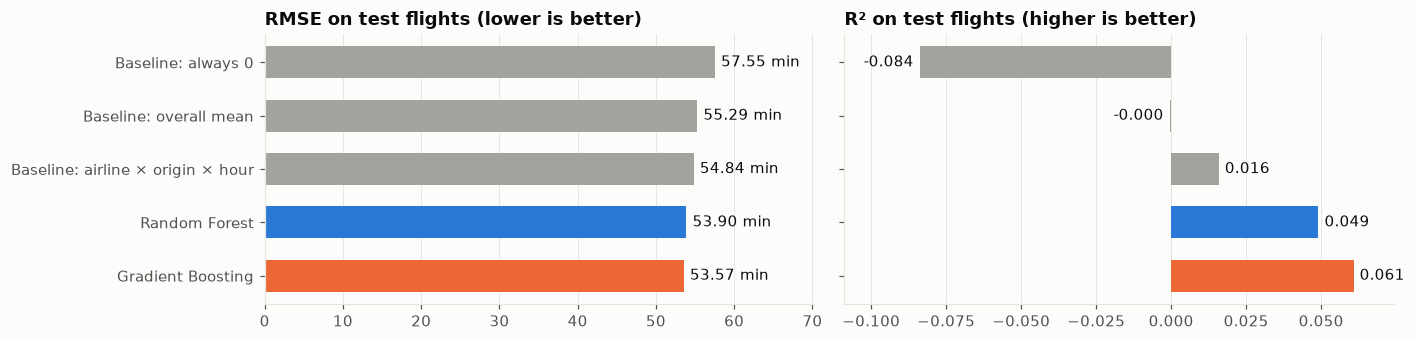

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.2), sharey=True)
names = list(preds)
for ax, metric, fmt, title in [(axes[0], "RMSE", "{:.2f} min", "RMSE on test flights (lower is better)"),
                               (axes[1], "R²", "{:.3f}", "R² on test flights (higher is better)")]:
    vals = results.loc[names, metric]
    bars = ax.barh(names, vals, color=[COLORS[n] for n in names], height=0.6)
    ax.bar_label(bars, labels=[fmt.format(v) for v in vals], padding=4, color=INK)
    ax.grid(axis="y", visible=False)
    ax.set(title=title)
    lo = min(0, vals.min())
    ax.set_xlim(lo * 1.3 if lo < 0 else 0, vals.max() * 1.22)
axes[0].invert_yaxis()
fig.tight_layout()
plt.show()

### Where the errors come from

,share of flights,Baseline: always 0,Baseline: airline × origin × hour,Random Forest,Gradient Boosting
delay_min,,,,,
0 (on time),62.5%,0.000000,13.344284,12.559430,11.965318
1–15,17.4%,6.499692,9.905945,10.213737,10.614340
16–60,13.0%,32.115763,16.375374,16.364377,17.034283
61–180,5.8%,100.696785,82.069199,77.331544,74.998162
180+,1.4%,341.225191,323.093964,316.085929,311.534578


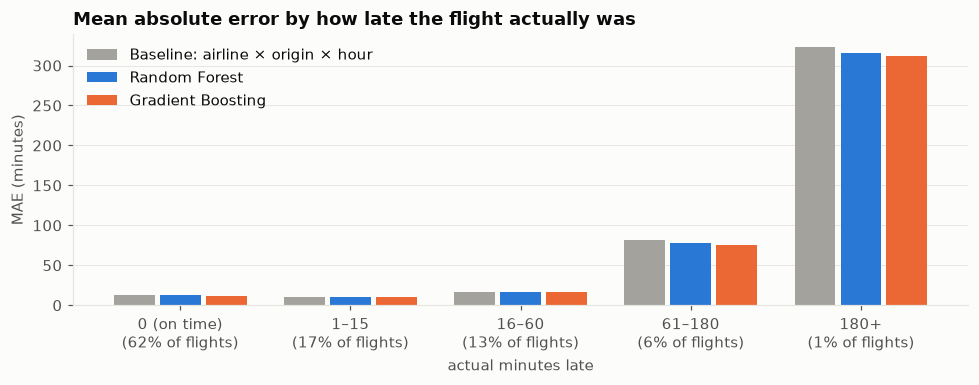

In [16]:
buckets = pd.cut(test["delay_min"], [-1, 0, 15, 60, 180, np.inf],
                 labels=["0 (on time)", "1–15", "16–60", "61–180", "180+"])
by_bucket = pd.DataFrame({name: pd.Series(np.abs(p - y_test), index=test.index).groupby(buckets, observed=True).mean()
                          for name, p in preds.items() if name != "Baseline: overall mean"})
by_bucket.insert(0, "share of flights", buckets.value_counts(normalize=True).reindex(by_bucket.index))
display(by_bucket.style.format("{:.1f}").format({"share of flights": "{:.1%}"}))

fig, ax = plt.subplots(figsize=(9, 3.6))
series = ["Baseline: airline × origin × hour", "Random Forest", "Gradient Boosting"]
x = np.arange(len(by_bucket))
width = 0.27
for i, name in enumerate(series):
    ax.bar(x + (i - 1) * width, by_bucket[name], width=width - 0.03, color=COLORS[name], label=name)
ax.set_xticks(x, [f"{b}\n({s:.0%} of flights)" for b, s in zip(by_bucket.index, by_bucket["share of flights"])])
ax.set(title="Mean absolute error by how late the flight actually was", xlabel="actual minutes late", ylabel="MAE (minutes)")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

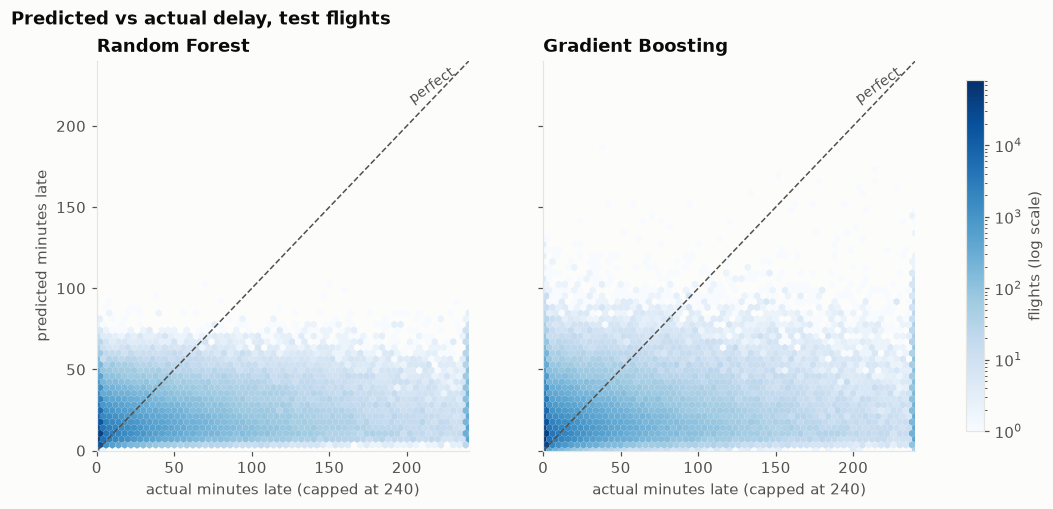

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
for ax, name in zip(axes, ["Random Forest", "Gradient Boosting"]):
    hb = ax.hexbin(np.clip(y_test, 0, 240), np.clip(preds[name], 0, 240), gridsize=60, bins="log",
                   cmap="Blues", mincnt=1, extent=(0, 240, 0, 240), linewidths=0)
    ax.plot([0, 240], [0, 240], color=INK_2, linewidth=1, linestyle="--")
    ax.text(200, 214, "perfect", color=INK_2, fontsize=9, rotation=35)
    ax.set(title=name, xlabel="actual minutes late (capped at 240)", xlim=(0, 240), ylim=(0, 240))
    ax.grid(False)
axes[0].set_ylabel("predicted minutes late")
fig.colorbar(hb, ax=axes, label="flights (log scale)", shrink=0.9)
fig.suptitle("Predicted vs actual delay, test flights", x=0.06, ha="left", fontweight="bold")
plt.show()

Both models predict cautiously, mostly in the 5–40 minute range. That's expected: the inputs describe the *day* (weather, traffic, the carrier's recent record), not the events that cause a particular 3-hour delay, like a broken part or a crew timing out. So the best guess for any one flight stays close to the typical delay for flights like it. The models rank flights well (bad-weather days and evening flights come out higher), even though they can't call the exact size of the long delays.

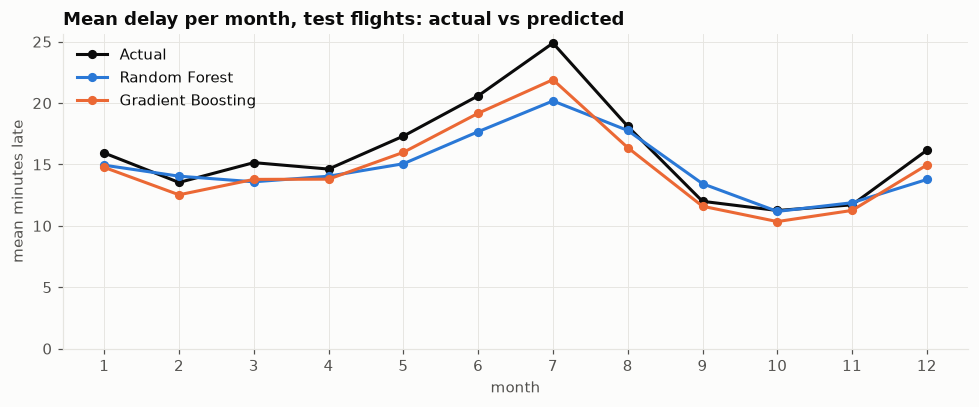

In [18]:
monthly = (pd.DataFrame({"Actual": y_test, "Random Forest": preds["Random Forest"],
                         "Gradient Boosting": preds["Gradient Boosting"], "month": test["month"].to_numpy()})
           .groupby("month").mean())
fig, ax = plt.subplots(figsize=(9, 3.8))
for name, color in [("Actual", ACTUAL_COLOR), ("Random Forest", RF_COLOR), ("Gradient Boosting", HGB_COLOR)]:
    ax.plot(monthly.index, monthly[name], color=color, marker="o", markersize=5, label=name)
ax.set(title="Mean delay per month, test flights: actual vs predicted", xlabel="month", ylabel="mean minutes late",
       xticks=range(1, 13))
ax.set_ylim(bottom=0)
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

In [19]:
frame = pd.DataFrame({"airline": test["airline"].astype(str), "actual": y_test,
                      "rf": preds["Random Forest"], "gb": preds["Gradient Boosting"]})
by_airline = frame.groupby("airline").apply(lambda g: pd.Series({
    "flights": len(g), "mean actual delay": g["actual"].mean(),
    "Random Forest mean prediction": g["rf"].mean(), "Gradient Boosting mean prediction": g["gb"].mean(),
    "Random Forest RMSE": root_mean_squared_error(g["actual"], g["rf"]),
    "Gradient Boosting RMSE": root_mean_squared_error(g["actual"], g["gb"])}), include_groups=False)
by_airline = by_airline.sort_values("flights", ascending=False)
by_airline.style.format("{:.1f}").format({"flights": "{:,.0f}"}).set_caption(
    "By airline, test flights: do the predictions track each carrier's real average delay?")

,flights,mean actual delay,Random Forest mean prediction,Gradient Boosting mean prediction,Random Forest RMSE,Gradient Boosting RMSE
airline,,,,,,
WN,"84,505",13.926691,13.868645,13.802607,30.491718,30.113209
DL,"59,686",13.775374,12.566369,12.707636,47.724055,47.243591
AA,"56,882",21.721388,18.120972,18.601422,79.091285,78.896334
UA,"44,748",15.503016,14.713633,14.547614,48.313619,47.736624
OO,"44,328",15.443760,13.371520,13.674957,60.458380,60.160246
YX,"18,447",10.292243,11.238822,10.195040,36.312777,35.744142
MQ,"16,019",11.991323,12.945868,11.607052,39.881773,39.757657
AS,"14,470",11.622252,12.283435,11.218762,33.248237,33.026749
B6,"14,374",23.214485,21.082402,21.489098,61.661875,60.864694


## 9 · Which features matter?

**Permutation importance:** shuffle one feature's column so it no longer lines up with the right flights, and measure how much worse the test RMSE gets. A large increase means the model relies on that feature. This is computed on 30,000 random test flights.

In [20]:
imp_sample = test.sample(min(30_000, len(test)), random_state=RANDOM_STATE)
X_imp, y_imp = imp_sample[FEATURES], imp_sample["delay_min"]
GROUP_OF = {f: g for g, cols in FEATURE_GROUPS.items() for f in cols}

importance = {}
for name, model in [("Random Forest", rf), ("Gradient Boosting", hgb)]:
    start = time.time()
    r = permutation_importance(model, X_imp, y_imp, scoring="neg_root_mean_squared_error",
                               n_repeats=3, random_state=RANDOM_STATE)
    importance[name] = pd.Series(r.importances_mean, index=FEATURES)
    print(f"{name}: {time.time() - start:.0f}s")
importance = pd.DataFrame(importance)
importance["group"] = importance.index.map(GROUP_OF)
importance.sort_values("Gradient Boosting", ascending=False).head(20)

Random Forest: 34s


Gradient Boosting: 43s


,Random Forest,Gradient Boosting,group
dep_hour,0.429,0.531,Schedule
origin,0.044,0.409,Schedule
dest,0.025,0.313,Schedule
month,0.093,0.274,Schedule
airline,0.122,0.173,Schedule
day_of_month,0.022,0.162,Schedule
origin_temp_max_f,0.123,0.151,Weather
origin_precip_in,0.154,0.150,Weather
day_of_week,0.034,0.122,Schedule
origin_weather_code,0.110,0.117,Weather


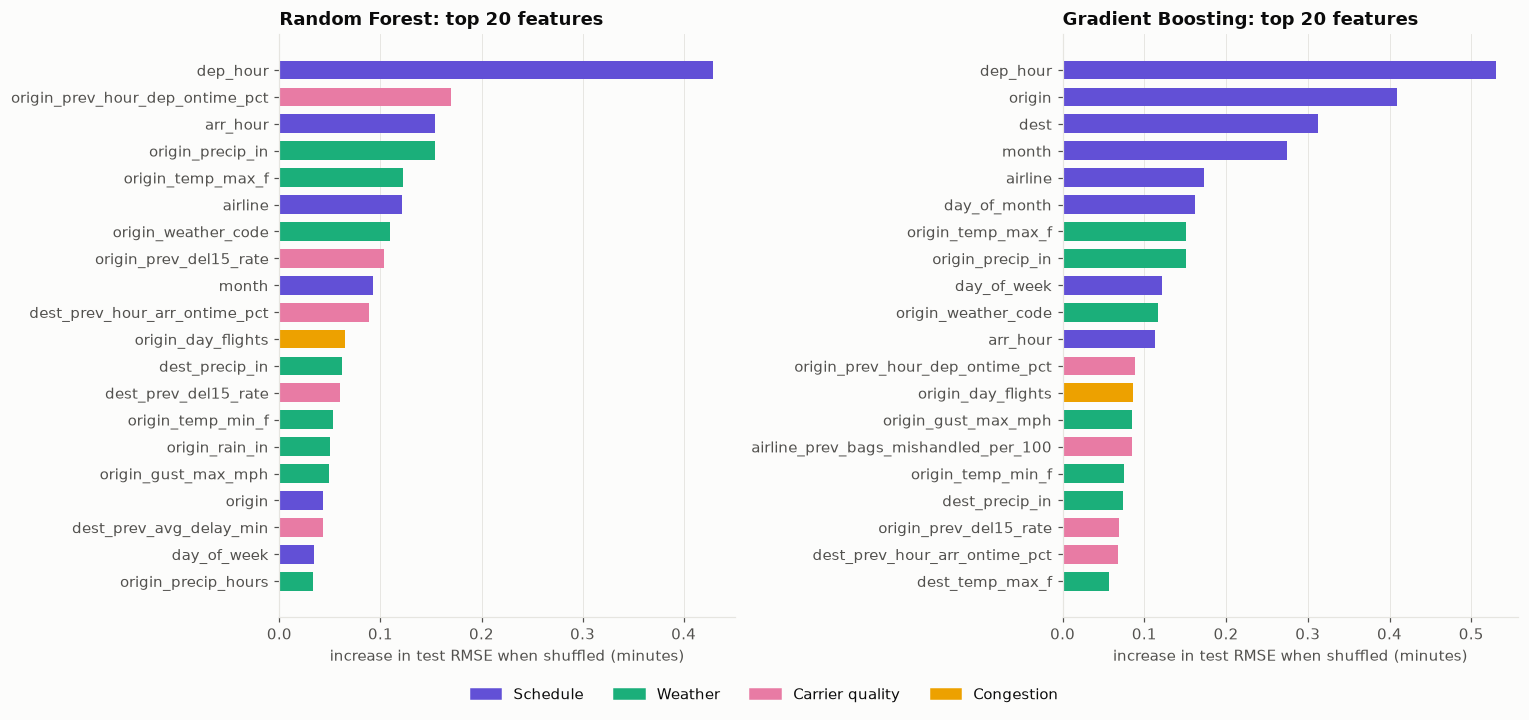

In [21]:
# Group colors are distinct from the model colors (blue/orange) so no hue means two things.
GROUP_COLORS = {"Schedule": "#6250d6", "Weather": "#1baf7a", "Carrier quality": "#e87ba4", "Congestion": "#eda100"}
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
for ax, name in zip(axes, ["Random Forest", "Gradient Boosting"]):
    top = importance.sort_values(name, ascending=False).head(20)[::-1]
    ax.barh(top.index, top[name], color=top["group"].map(GROUP_COLORS), height=0.7)
    ax.set(title=f"{name}: top 20 features", xlabel="increase in test RMSE when shuffled (minutes)")
    ax.grid(axis="y", visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in GROUP_COLORS.values()]
fig.legend(handles, GROUP_COLORS.keys(), loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.01))
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

Shuffling one feature at a time understates a group of features that carry overlapping information. For example, the origin and destination weather codes and precipitation all describe the same storm. So we also shuffle **each group as a whole** and measure the loss:

,Random Forest,Gradient Boosting
Schedule,1.00,1.83
Weather,1.09,1.49
Carrier quality,0.70,0.52
Congestion,0.08,0.11


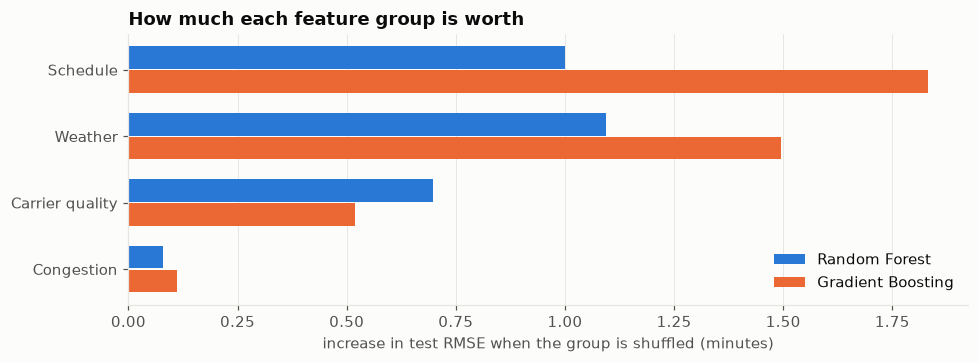

In [22]:
def group_importance(model, X, y, n_repeats=3):
    rng = np.random.default_rng(RANDOM_STATE)
    base = root_mean_squared_error(y, model.predict(X))
    out = {}
    for group, cols in FEATURE_GROUPS.items():
        increases = []
        for _ in range(n_repeats):
            order = rng.permutation(len(X))
            shuffled = X.copy()
            for c in cols:
                shuffled[c] = X[c].iloc[order].set_axis(X.index)
            increases.append(root_mean_squared_error(y, model.predict(shuffled)) - base)
        out[group] = np.mean(increases)
    return pd.Series(out)


group_imp = pd.DataFrame({name: group_importance(model, X_imp, y_imp)
                          for name, model in [("Random Forest", rf), ("Gradient Boosting", hgb)]})
display(group_imp.style.format("{:.2f}").set_caption("Increase in test RMSE (minutes) when the whole group is shuffled"))

fig, ax = plt.subplots(figsize=(9, 3.4))
y = np.arange(len(group_imp))
ax.barh(y - 0.18, group_imp["Random Forest"], height=0.34, color=RF_COLOR, label="Random Forest")
ax.barh(y + 0.18, group_imp["Gradient Boosting"], height=0.34, color=HGB_COLOR, label="Gradient Boosting")
ax.set_yticks(y, group_imp.index)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set(title="How much each feature group is worth", xlabel="increase in test RMSE when the group is shuffled (minutes)")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

### Ablation: retrain without weather or carrier quality

Shuffling shows what a *trained* model relies on. The stricter question is whether a model could do as well **without** those features, by learning from the others instead. Gradient boosting is fast enough to retrain, so we refit it with the same settings, leaving one group out each time.

In [23]:
ablation = {"All features": results.loc["Gradient Boosting", "RMSE"]}
for dropped in ["Weather", "Carrier quality", "Congestion"]:
    keep = [f for f in FEATURES if f not in FEATURE_GROUPS[dropped]]
    start = time.time()
    m = make_hgb(**HGB_BEST).fit(train[keep], y_fit(train))
    ablation[f"Without {dropped.lower()}"] = root_mean_squared_error(y_test, m.predict(test[keep]))
    print(f"without {dropped}: {time.time() - start:.0f}s")
keep = [f for f in FEATURES if f not in FEATURE_GROUPS["Weather"] + FEATURE_GROUPS["Carrier quality"]]
m = make_hgb(**HGB_BEST).fit(train[keep], y_fit(train))
ablation["Without weather and carrier quality"] = root_mean_squared_error(y_test, m.predict(test[keep]))

ablation = pd.DataFrame({"test RMSE": ablation})
ablation["vs all features"] = ablation["test RMSE"] - ablation.loc["All features", "test RMSE"]
ablation.style.format({"test RMSE": "{:.2f}", "vs all features": "{:+.2f}"})

without Weather: 46s


without Carrier quality: 72s


without Congestion: 97s


,test RMSE,vs all features
All features,53.57,+0.00
Without weather,54.11,+0.54
Without carrier quality,53.62,+0.05
Without congestion,53.57,+0.00
Without weather and carrier quality,54.17,+0.60


## 10 · Save the models

In [24]:
joblib.dump(rf, MODEL_DIR / "random_forest.joblib", compress=3)
joblib.dump(hgb, MODEL_DIR / "gradient_boosting.joblib", compress=3)
meta = {
    "target": "delay_min = max(dep_delay, 0), minutes",
    "features": FEATURES,
    "feature_groups": FEATURE_GROUPS,
    "categorical": CATEGORICAL,
    "categorical_levels": {c: KEPT_LEVELS[c] + ["OTHER"] for c in CATEGORICAL},
    "derived": {"dep_hour": "sched_dep_time // 100 % 24", "arr_hour": "sched_arr_time // 100 % 24",
                "*_storm": "weather_code >= 95", "*_snow": "weather_code in 71-77 or 85-86",
                "origin_day_flights": "scheduled departures at the origin that day",
                "origin_hour_flights": "scheduled departures at the origin in that hour"},
    "training_clip_minutes": CLIP_MIN,
    "split": "random 80/20 over 2023-2025", "test_fraction": 0.2, "split_seed": RANDOM_STATE, "sample_rate": SAMPLE_RATE,
    "random_forest_params": RF_BEST, "gradient_boosting_params": {**HGB_BEST, "trees": int(hgb.n_iter_)},
    "test_scores": results.drop(columns="RMSE vs overall mean").round(4).to_dict(orient="index"),
}
(MODEL_DIR / "feature_list.json").write_text(json.dumps(meta, indent=2))
for f in ["random_forest.joblib", "gradient_boosting.joblib", "feature_list.json"]:
    print(f"{MODEL_DIR / f}  ({(MODEL_DIR / f).stat().st_size / 1e6:.1f} MB)")

C:\Users\Jbeck\flight_data\models\random_forest.joblib  (75.9 MB)
C:\Users\Jbeck\flight_data\models\gradient_boosting.joblib  (3.6 MB)
C:\Users\Jbeck\flight_data\models\feature_list.json  (0.0 MB)


## 11 · Conclusions

**Gradient Boosting is the better model, and it's the one to use on the departures board.** On the 411,465 held-out test flights, it beats the Random Forest on every overall score:

| | RMSE (min) | R² | MAE (min) | ROC AUC, 15+ min late |
| --- | --- | --- | --- | --- |
| Baseline: overall mean | 55.29 | 0.000 | 22.55 | 0.500 |
| Baseline: airline × origin × hour | 54.84 | 0.016 | 21.54 | 0.652 |
| Random Forest | 53.90 | 0.049 | 20.73 | 0.708 |
| **Gradient Boosting** | **53.57** | **0.061** | **20.32** | **0.713** |

It's also more practical: its final fit took 1.4 minutes against 9.5 for the forest, and the saved model is 3.6 MB against 76 MB.

**Where they differ.** Gradient Boosting has the smaller error on on-time flights and on long delays (61–180 and 180+ minutes). The Random Forest is a little closer on flights 1–60 minutes late, because its predictions sit nearer the middle. For every airline, both models' average prediction is within a few minutes of the real average delay. Both run low for the carriers with the most delays, such as AA, OH and F9.

**How good is it?** Modest, and that's expected. The models explain about 6% of the flight-to-flight variation in delay. They rank flights much better than that number suggests: AUC 0.71 for picking out flights that leave 15+ minutes late, against 0.65 for the historical lookup table. The inputs describe the day and the route, not one-off events like a mechanical problem or a crew timing out, which cause most of the long delays.

**It works as a risk score, not an exact forecast.** Sorting the test flights by predicted delay and splitting them into ten equal groups shows how well the model separates safe flights from risky ones:

| Group (by predicted delay) | Predicted avg | Actual avg | Left 15+ min late | Left 60+ min late |
| --- | --- | --- | --- | --- |
| Lowest 10% | 2 min | 4 min | 6% | 2% |
| Middle (5th) | 11 min | 11 min | 16% | 5% |
| Highest 10% | 42 min | 49 min | 51% | 25% |
| All flights | | | 21% | 7% |

A flight in the highest-risk group is 8 times as likely to leave 15+ minutes late as one in the lowest group, and about 15 times as likely to leave an hour or more late. Each group's predicted average is also within a few minutes of its actual average.

**Very long delays are predicted inaccurately, but they're still predicted to be late.** For flights that actually left 3+ hours late (1.4% of test flights, averaging 341 minutes), the model predicted only 30 minutes on average. It can't foresee what causes those delays, like a mechanical problem or a crew running out of hours, so its minutes are far too low. But it still marks these flights as risky:

| Actual delay | Flights | Actual avg | Predicted avg | Predicted above the typical flight* | In the model's riskiest 20% | In the model's riskiest 10% |
| --- | --- | --- | --- | --- | --- | --- |
| On time | 256,961 | 0 min | 12 min | 40% | 12% | 5% |
| 1–15 min | 71,390 | 7 min | 16 min | 58% | 23% | 11% |
| 16–60 min | 53,411 | 32 min | 20 min | 71% | 36% | 20% |
| 61–180 min | 23,828 | 101 min | 26 min | 79% | 50% | 33% |
| 180+ min | 5,875 | 341 min | 30 min | 78% | 54% | 40% |

\*above the median prediction of 11.5 minutes.

Over half of the 3+ hour delays land in the riskiest fifth of flights, and 40% in the riskiest tenth, which is four times the share if the model were guessing. The model gets the direction right on long delays but badly underestimates their size. That's why the departures board should show a chance of delay or a low/medium/high label, not a promised number of minutes.

**What drives the predictions.** Departure hour, airport, month and weather matter most. Retraining without weather costs the most (+0.54 min RMSE). Leaving out last month's carrier quality costs almost nothing (+0.05), because the airline, airport and hour already carry much of the same information, and the congestion counts add nothing measurable.

**Caveats.** The split is random, so flights from the same day are in both training and test. That, plus using observed instead of forecast weather, makes these scores a little better than the model's accuracy on future flights.
